In [1]:
# Cell 1: Additional imports for metadata parsing

import re
from collections import Counter, defaultdict

import scipy.io as sio

try:
    import mne
    MNE_AVAILABLE = True
except ImportError:
    MNE_AVAILABLE = False

print("MNE available:", MNE_AVAILABLE)

MNE available: True


In [2]:
# Cell 1: Imports, reproducibility, and publication-grade plotting

from pathlib import Path
import os
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import tensorflow as tf

SEED = 42

def set_seed(seed: int = 42):
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)

set_seed(SEED)

# -----------------------------
# Publication-grade plotting style
# -----------------------------
mpl.rcParams.update({
    "figure.figsize": (8, 5),
    "figure.dpi": 140,
    "savefig.dpi": 600,
    "savefig.bbox": "tight",
    "savefig.pad_inches": 0.05,

    "font.size": 11,
    "axes.titlesize": 12,
    "axes.labelsize": 11,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 9,

    "axes.linewidth": 0.8,
    "lines.linewidth": 1.8,
    "lines.markersize": 5,

    "xtick.major.width": 0.8,
    "ytick.major.width": 0.8,
    "xtick.minor.width": 0.6,
    "ytick.minor.width": 0.6,

    "xtick.direction": "out",
    "ytick.direction": "out",

    "axes.spines.top": False,
    "axes.spines.right": False,

    "axes.grid": False,
    "legend.frameon": False,
    "image.cmap": "viridis",
})

# Colorblind-friendly palette
CB_COLORS = [
    "#0072B2",  # blue
    "#D55E00",  # vermillion
    "#009E73",  # green
    "#CC79A7",  # purple
    "#E69F00",  # orange
    "#56B4E9",  # sky blue
    "#F0E442",  # yellow
    "#000000",  # black
]

print("TensorFlow version:", tf.__version__)
print("Setup complete with publication-grade plotting.")

2026-03-30 08:22:23.922589: I tensorflow/core/util/port.cc:113] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-03-30 08:22:23.959993: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


TensorFlow version: 2.16.1
Setup complete with publication-grade plotting.


In [3]:
# Cell 1B: Save figures in manuscript-friendly formats

def save_figure(fig, out_dir, stem_name):
    out_dir = Path(out_dir)
    out_dir.mkdir(parents=True, exist_ok=True)

    png_path = out_dir / f"{stem_name}.png"
    pdf_path = out_dir / f"{stem_name}.pdf"

    fig.savefig(png_path, dpi=600, bbox_inches="tight")
    fig.savefig(pdf_path, bbox_inches="tight")

    print("Saved:")
    print(" -", png_path)
    print(" -", pdf_path)

In [4]:
# Cell 2: Project paths

PROJECT_ROOT = Path.cwd().resolve().parents[0] if "notebooks" in str(Path.cwd()) else Path.cwd()

DATA_DIR = PROJECT_ROOT / "data"
RAW_DIR = DATA_DIR / "raw"

CHBMIT_DIR = RAW_DIR / "chbmit"
TURKISH_DIR = RAW_DIR / "turkish"

OUTPUT_DIR = PROJECT_ROOT / "outputs"
FIG_DIR = OUTPUT_DIR / "figures"
TABLE_DIR = OUTPUT_DIR / "tables"
LOG_DIR = OUTPUT_DIR / "logs"
MODEL_DIR = OUTPUT_DIR / "models"

for d in [FIG_DIR, TABLE_DIR, LOG_DIR, MODEL_DIR]:
    d.mkdir(parents=True, exist_ok=True)

print("PROJECT_ROOT:", PROJECT_ROOT)
print("CHBMIT_DIR exists:", CHBMIT_DIR.exists(), CHBMIT_DIR)
print("TURKISH_DIR exists:", TURKISH_DIR.exists(), TURKISH_DIR)

PROJECT_ROOT: /home/harman/projects/Sachin_Epilepsy_Revised
CHBMIT_DIR exists: True /home/harman/projects/Sachin_Epilepsy_Revised/data/raw/chbmit
TURKISH_DIR exists: True /home/harman/projects/Sachin_Epilepsy_Revised/data/raw/turkish


In [5]:
def list_files_recursive(root: Path, max_items: int = 30):
    if not root.exists():
        print(f"Path does not exist: {root}")
        return []
    
    files = [p for p in root.rglob("*") if p.is_file()]
    files = sorted(files)
    
    print(f"\nFolder: {root}")
    print(f"Total files found: {len(files)}")
    print("Sample files:")
    for p in files[:max_items]:
        print(" -", p.relative_to(root))
    return files

chbmit_files = list_files_recursive(CHBMIT_DIR, max_items=20)
turkish_files = list_files_recursive(TURKISH_DIR, max_items=20)


Folder: /home/harman/projects/Sachin_Epilepsy_Revised/data/raw/chbmit
Total files found: 2139
Sample files:
 - ANNOTATORS
 - ANNOTATORS:Zone.Identifier
 - RECORDS
 - RECORDS-WITH-SEIZURES
 - RECORDS-WITH-SEIZURES:Zone.Identifier
 - RECORDS-WITH-SEIZURES:Zone.Identifier:Zone.Identifier
 - RECORDS:Zone.Identifier
 - RECORDS:Zone.Identifier:Zone.Identifier
 - SHA256SUMS.txt
 - SHA256SUMS.txt:Zone.Identifier
 - SHA256SUMS.txt:Zone.Identifier:Zone.Identifier
 - SUBJECT-INFO
 - SUBJECT-INFO:Zone.Identifier
 - SUBJECT-INFO:Zone.Identifier:Zone.Identifier
 - chb01/chb01-summary.txt
 - chb01/chb01-summary.txt:Zone.Identifier
 - chb01/chb01_01.edf
 - chb01/chb01_01.edf:Zone.Identifier
 - chb01/chb01_02.edf
 - chb01/chb01_02.edf:Zone.Identifier

Folder: /home/harman/projects/Sachin_Epilepsy_Revised/data/raw/turkish
Total files found: 242
Sample files:
 - epilepsy/1_epilepsy (1).mat
 - epilepsy/1_epilepsy (1).mat:Zone.Identifier
 - epilepsy/1_epilepsy (10).mat
 - epilepsy/1_epilepsy (10).mat:Zone

In [6]:
# Cell 2: Clean raw file lists by excluding Windows metadata artifacts

from pathlib import Path
def is_windows_artifact(path: Path) -> bool:
    name = path.name.lower()
    return "zone.identifier" in name

def filter_real_files(file_list):
    return [p for p in file_list if not is_windows_artifact(p)]

chbmit_files_clean = filter_real_files(chbmit_files)
turkish_files_clean = filter_real_files(turkish_files)

print("CHB-MIT raw files:", len(chbmit_files), "-> cleaned:", len(chbmit_files_clean))
print("Turkish raw files:", len(turkish_files), "-> cleaned:", len(turkish_files_clean))

CHB-MIT raw files: 2139 -> cleaned: 857
Turkish raw files: 242 -> cleaned: 121


In [7]:
# Cell 3: Build cleaned inventory table
import pandas as pd
def summarize_extensions(file_list):
    ext_counts = {}
    for f in file_list:
        ext = f.suffix.lower() if f.suffix else "[no_ext]"
        ext_counts[ext] = ext_counts.get(ext, 0) + 1
    return ext_counts

chbmit_ext_clean = summarize_extensions(chbmit_files_clean)
turkish_ext_clean = summarize_extensions(turkish_files_clean)

clean_rows = []
for dataset_name, ext_dict, total in [
    ("CHB-MIT", chbmit_ext_clean, len(chbmit_files_clean)),
    ("Turkish", turkish_ext_clean, len(turkish_files_clean)),
]:
    for ext, count in sorted(ext_dict.items(), key=lambda x: x[0]):
        clean_rows.append({
            "dataset": dataset_name,
            "file_extension": ext,
            "count": count,
            "total_files": total
        })

inventory_clean_df = pd.DataFrame(clean_rows)
inventory_clean_df

,dataset,file_extension,count,total_files
0,CHB-MIT,.edf,686,857
1,CHB-MIT,.pdf,1,857
2,CHB-MIT,.seizures,141,857
3,CHB-MIT,.txt,25,857
4,CHB-MIT,[no_ext],4,857
5,Turkish,.mat,121,121


Saved:
 - /home/harman/projects/Sachin_Epilepsy_Revised/outputs/figures/fig03_clean_filetype_distribution.png
 - /home/harman/projects/Sachin_Epilepsy_Revised/outputs/figures/fig03_clean_filetype_distribution.pdf


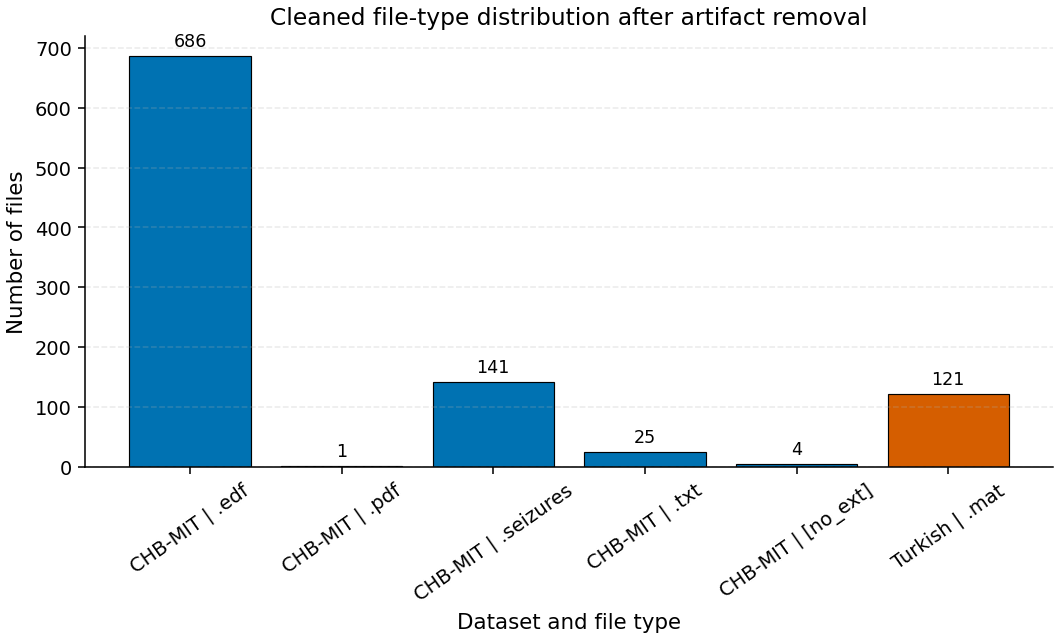

In [8]:
# Cell 4: Cleaned file-type distribution plot

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7.8, 4.8))

plot_df = inventory_clean_df.copy()
plot_df["label"] = plot_df["dataset"] + " | " + plot_df["file_extension"]

bars = ax.bar(
    plot_df["label"],
    plot_df["count"],
    color=[CB_COLORS[0] if d == "CHB-MIT" else CB_COLORS[1] for d in plot_df["dataset"]],
    edgecolor="black",
    linewidth=0.6
)

ax.set_ylabel("Number of files")
ax.set_xlabel("Dataset and file type")
ax.set_title("Cleaned file-type distribution after artifact removal")
ax.tick_params(axis="x", rotation=35)
ax.grid(axis="y", linestyle="--", alpha=0.25)

for bar in bars:
    height = bar.get_height()
    ax.annotate(
        f"{int(height)}",
        xy=(bar.get_x() + bar.get_width() / 2, height),
        xytext=(0, 3),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=9
    )

plt.tight_layout()
save_figure(fig, FIG_DIR, "fig03_clean_filetype_distribution")
plt.show()

In [9]:
# Cell 5: CHB-MIT subject-level inventory

chbmit_edf_files = sorted([p for p in chbmit_files_clean if p.suffix.lower() == ".edf"])
chbmit_seizure_files = sorted([p for p in chbmit_files_clean if p.suffix.lower() == ".seizures"])
chbmit_txt_files = sorted([p for p in chbmit_files_clean if p.suffix.lower() == ".txt"])

def get_chbmit_subject_from_path(path: Path):
    parent = path.parent.name.lower()
    if parent.startswith("chb"):
        return parent
    return "global"

subject_stats = defaultdict(lambda: {
    "edf_count": 0,
    "seizure_file_count": 0,
    "summary_txt_count": 0
})

for f in chbmit_edf_files:
    subject = get_chbmit_subject_from_path(f)
    subject_stats[subject]["edf_count"] += 1

for f in chbmit_seizure_files:
    subject = get_chbmit_subject_from_path(f)
    subject_stats[subject]["seizure_file_count"] += 1

for f in chbmit_txt_files:
    subject = get_chbmit_subject_from_path(f)
    subject_stats[subject]["summary_txt_count"] += 1

chbmit_subject_df = (
    pd.DataFrame.from_dict(subject_stats, orient="index")
    .reset_index()
    .rename(columns={"index": "subject_id"})
    .sort_values("subject_id")
    .reset_index(drop=True)
)

chbmit_subject_df.head(15)

,subject_id,edf_count,seizure_file_count,summary_txt_count
0,chb01,42,7,1
1,chb02,36,3,1
2,chb03,38,7,1
3,chb04,42,3,1
4,chb05,39,5,1
5,chb06,18,7,1
6,chb07,19,3,1
7,chb08,20,5,1
8,chb09,19,3,1
9,chb10,25,7,1


Saved:
 - /home/harman/projects/Sachin_Epilepsy_Revised/outputs/figures/fig04_chbmit_recordings_per_subject.png
 - /home/harman/projects/Sachin_Epilepsy_Revised/outputs/figures/fig04_chbmit_recordings_per_subject.pdf


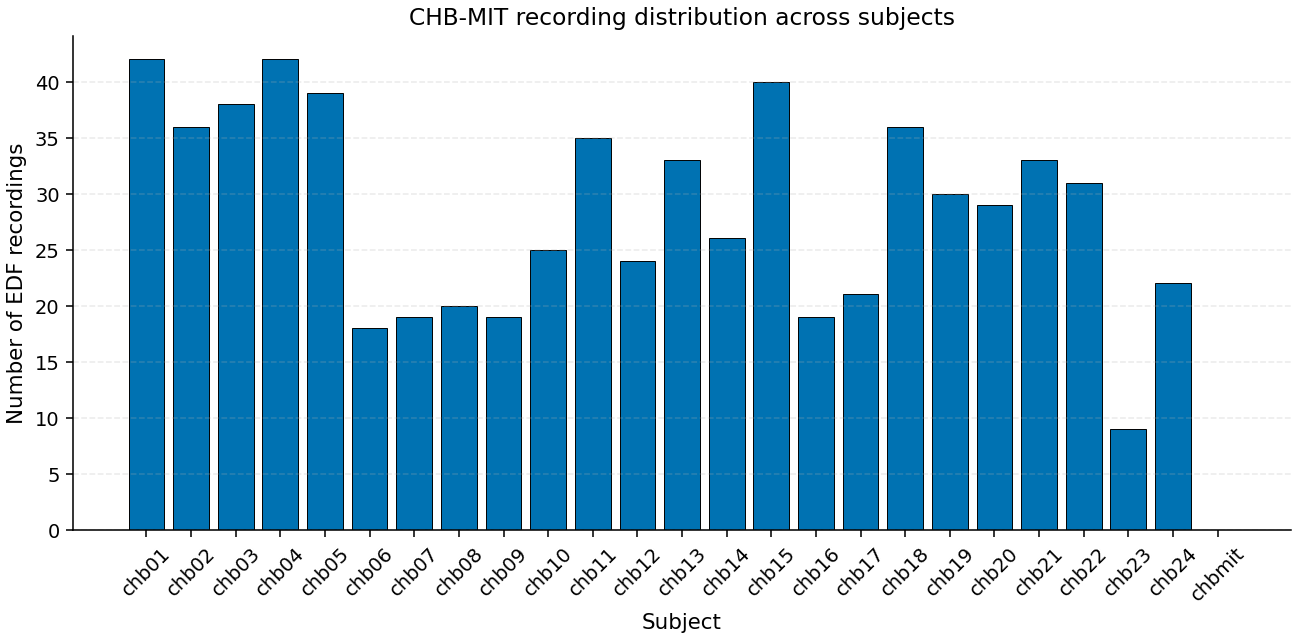

In [10]:
# Cell 6: CHB-MIT EDF recordings per subject

plot_df = chbmit_subject_df[chbmit_subject_df["subject_id"] != "global"].copy()

fig, ax = plt.subplots(figsize=(9.5, 4.8))

bars = ax.bar(
    plot_df["subject_id"],
    plot_df["edf_count"],
    color=CB_COLORS[0],
    edgecolor="black",
    linewidth=0.5
)

ax.set_ylabel("Number of EDF recordings")
ax.set_xlabel("Subject")
ax.set_title("CHB-MIT recording distribution across subjects")
ax.tick_params(axis="x", rotation=45)
ax.grid(axis="y", linestyle="--", alpha=0.25)

plt.tight_layout()
save_figure(fig, FIG_DIR, "fig04_chbmit_recordings_per_subject")
plt.show()

In [11]:
# Cell 7: Turkish dataset inventory by class/folder

turkish_mat_files = sorted([p for p in turkish_files_clean if p.suffix.lower() == ".mat"])

turkish_rows = []
for f in turkish_mat_files:
    class_label = f.parent.name.lower()
    turkish_rows.append({
        "file_name": f.name,
        "class_label": class_label,
        "stem": f.stem
    })

turkish_df = pd.DataFrame(turkish_rows)
turkish_df.head()

,file_name,class_label,stem
0,1_epilepsy (1).mat,epilepsy,1_epilepsy (1)
1,1_epilepsy (10).mat,epilepsy,1_epilepsy (10)
2,1_epilepsy (11).mat,epilepsy,1_epilepsy (11)
3,1_epilepsy (12).mat,epilepsy,1_epilepsy (12)
4,1_epilepsy (13).mat,epilepsy,1_epilepsy (13)


In [13]:
turkish_class_counts = (
    turkish_df["class_label"]
    .value_counts()
    .rename_axis("class_label")
    .reset_index(name="count")
)

turkish_class_counts

,class_label,count
0,normal,71
1,epilepsy,50


In [14]:
turkish_df.to_csv(TABLE_DIR / "turkish_file_inventory.csv", index=False)
turkish_class_counts.to_csv(TABLE_DIR / "turkish_class_counts.csv", index=False)
print("Saved Turkish inventory tables.")

Saved Turkish inventory tables.


Saved:
 - /home/harman/projects/Sachin_Epilepsy_Revised/outputs/figures/fig05_turkish_class_distribution.png
 - /home/harman/projects/Sachin_Epilepsy_Revised/outputs/figures/fig05_turkish_class_distribution.pdf


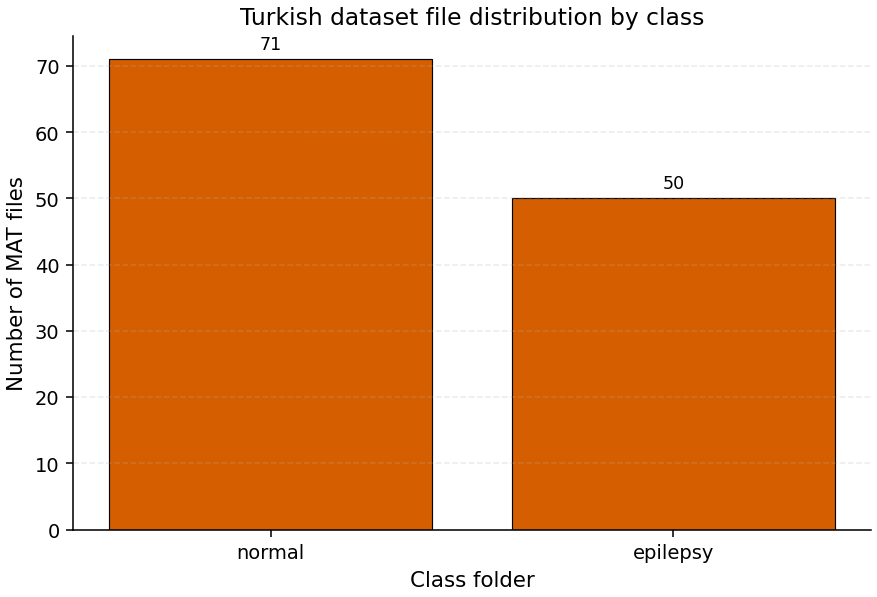

In [15]:
# Cell 8: Turkish dataset class distribution

fig, ax = plt.subplots(figsize=(6.5, 4.5))

bars = ax.bar(
    turkish_class_counts["class_label"],
    turkish_class_counts["count"],
    color=CB_COLORS[1],
    edgecolor="black",
    linewidth=0.6
)

ax.set_ylabel("Number of MAT files")
ax.set_xlabel("Class folder")
ax.set_title("Turkish dataset file distribution by class")
ax.grid(axis="y", linestyle="--", alpha=0.25)

for bar in bars:
    height = bar.get_height()
    ax.annotate(
        f"{int(height)}",
        xy=(bar.get_x() + bar.get_width() / 2, height),
        xytext=(0, 3),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=9
    )

plt.tight_layout()
save_figure(fig, FIG_DIR, "fig05_turkish_class_distribution")
plt.show()

In [16]:
# Cell 9: Inspect one EDF file header

sample_edf = chbmit_edf_files[0]
print("Sample EDF:", sample_edf)

if MNE_AVAILABLE:
    raw = mne.io.read_raw_edf(sample_edf, preload=False, verbose="ERROR")
    print("Number of channels:", len(raw.ch_names))
    print("Sampling frequency:", raw.info["sfreq"])
    print("First 10 channels:", raw.ch_names[:10])
else:
    print("MNE is not installed. Install it with: pip install mne")

Sample EDF: /home/harman/projects/Sachin_Epilepsy_Revised/data/raw/chbmit/chb01/chb01_01.edf
Number of channels: 23
Sampling frequency: 256.0
First 10 channels: ['FP1-F7', 'F7-T7', 'T7-P7', 'P7-O1', 'FP1-F3', 'F3-C3', 'C3-P3', 'P3-O1', 'FP2-F4', 'F4-C4']


In [17]:
# Cell 10: Inspect one Turkish MAT file structure

sample_mat = turkish_mat_files[0]
print("Sample MAT:", sample_mat)

def inspect_mat_file(mat_path):
    try:
        data = sio.loadmat(mat_path)
        keys = [k for k in data.keys() if not k.startswith("__")]
        print("MAT keys:", keys)
        for k in keys:
            obj = data[k]
            if hasattr(obj, "shape"):
                print(f"Key: {k}, shape: {obj.shape}, dtype: {obj.dtype}")
            else:
                print(f"Key: {k}, type: {type(obj)}")
        return data
    except Exception as e:
        print("Error loading MAT file:", e)
        return None

sample_mat_data = inspect_mat_file(sample_mat)

Sample MAT: /home/harman/projects/Sachin_Epilepsy_Revised/data/raw/turkish/epilepsy/1_epilepsy (1).mat
MAT keys: ['data', 'label']
Key: data, shape: (48, 36), dtype: object
Key: label, shape: (1, 48), dtype: uint8


In [18]:
# Cell 11: Preliminary dataset characteristics summary

n_chb_subjects = chbmit_subject_df[chbmit_subject_df["subject_id"] != "global"]["subject_id"].nunique()
n_chb_edf = len(chbmit_edf_files)
n_chb_seiz = len(chbmit_seizure_files)

n_turkish_mat = len(turkish_mat_files)
turkish_classes = ", ".join(sorted(turkish_class_counts["class_label"].unique()))

summary_rows = [
    {
        "dataset": "CHB-MIT",
        "n_subjects_or_cases": n_chb_subjects,
        "n_primary_signal_files": n_chb_edf,
        "annotation_or_aux_files": n_chb_seiz,
        "primary_format": ".edf",
        "class_structure": "subject folders"
    },
    {
        "dataset": "Turkish",
        "n_subjects_or_cases": n_turkish_mat,
        "n_primary_signal_files": n_turkish_mat,
        "annotation_or_aux_files": 0,
        "primary_format": ".mat",
        "class_structure": turkish_classes
    },
]

dataset_summary_df = pd.DataFrame(summary_rows)
dataset_summary_df

,dataset,n_subjects_or_cases,n_primary_signal_files,annotation_or_aux_files,primary_format,class_structure
0,CHB-MIT,25,686,141,.edf,subject folders
1,Turkish,121,121,0,.mat,"epilepsy, normal"


In [19]:
dataset_summary_df.to_csv(TABLE_DIR / "dataset_summary_preliminary.csv", index=False)
print("Saved:", TABLE_DIR / "dataset_summary_preliminary.csv")

Saved: /home/harman/projects/Sachin_Epilepsy_Revised/outputs/tables/dataset_summary_preliminary.csv


Saved:
 - /home/harman/projects/Sachin_Epilepsy_Revised/outputs/figures/fig06_dataset_characteristics_overview.png
 - /home/harman/projects/Sachin_Epilepsy_Revised/outputs/figures/fig06_dataset_characteristics_overview.pdf


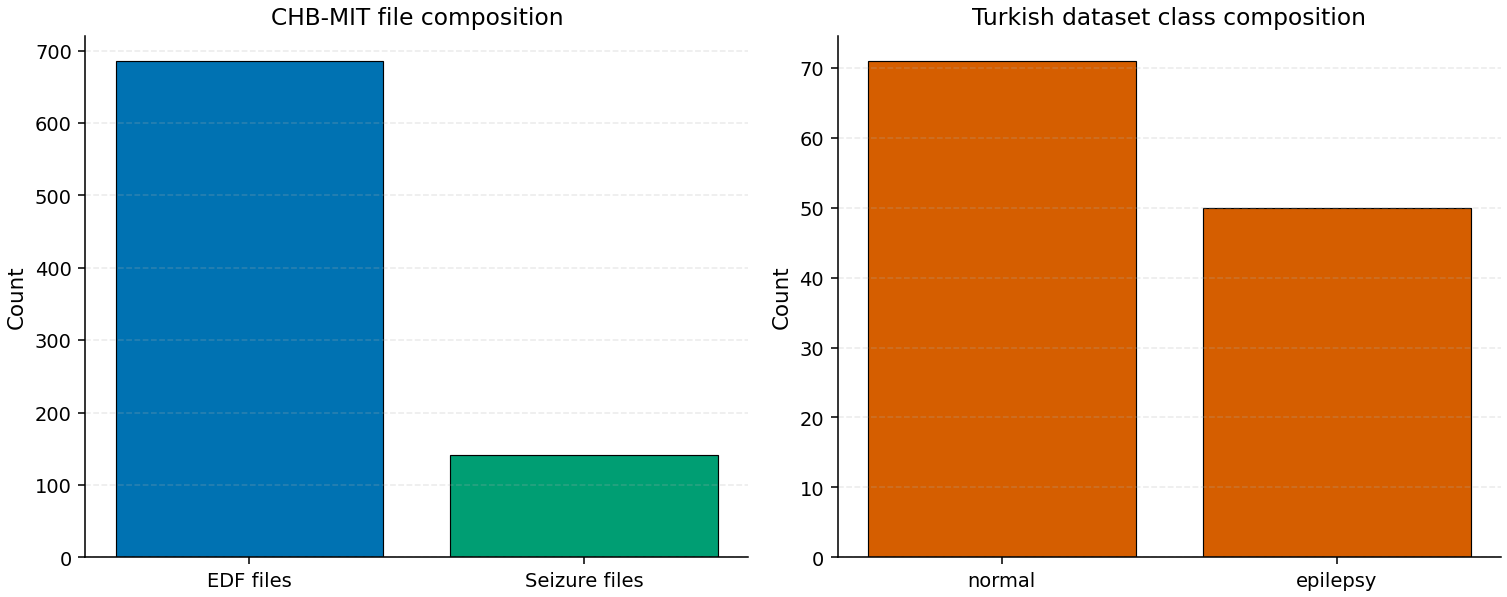

In [20]:
# Cell 12: Dataset characteristics overview figure

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

# Left panel: CHB-MIT counts
axes[0].bar(
    ["EDF files", "Seizure files"],
    [n_chb_edf, n_chb_seiz],
    color=[CB_COLORS[0], CB_COLORS[2]],
    edgecolor="black",
    linewidth=0.6
)
axes[0].set_title("CHB-MIT file composition")
axes[0].set_ylabel("Count")
axes[0].grid(axis="y", linestyle="--", alpha=0.25)

# Right panel: Turkish class counts
axes[1].bar(
    turkish_class_counts["class_label"],
    turkish_class_counts["count"],
    color=CB_COLORS[1],
    edgecolor="black",
    linewidth=0.6
)
axes[1].set_title("Turkish dataset class composition")
axes[1].set_ylabel("Count")
axes[1].grid(axis="y", linestyle="--", alpha=0.25)

plt.tight_layout()
save_figure(fig, FIG_DIR, "fig06_dataset_characteristics_overview")
plt.show()